In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display

from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

In [3]:
!pip install pandas numpy matplotlib seaborn ipywidgets catboost scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 51.8 MB/s eta 0:00:00


In [4]:
!pip install catboost ipywidgets

In [6]:
import pandas as pd

df = pd.read_excel('Online-Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
#Data Preprocessing
df.dropna(inplace=True)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df = df[df['Quantity'] > 0]
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [8]:
#Feature Engineering
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [10]:
#Train-Test Split
X = rfm[['Recency', 'Frequency', 'Monetary']]
y = np.where(rfm['Monetary'] > rfm['Monetary'].median(), 1, 0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((3471, 3), (868, 3), (3471,), (868,))

In [11]:
#Train the CatBoost Model
model = CatBoostClassifier(iterations=100, learning_rate=0.1, depth=6, verbose=False)

model.fit(X_train, y_train)

accuracy = model.score(X_test, y_test)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 1.00


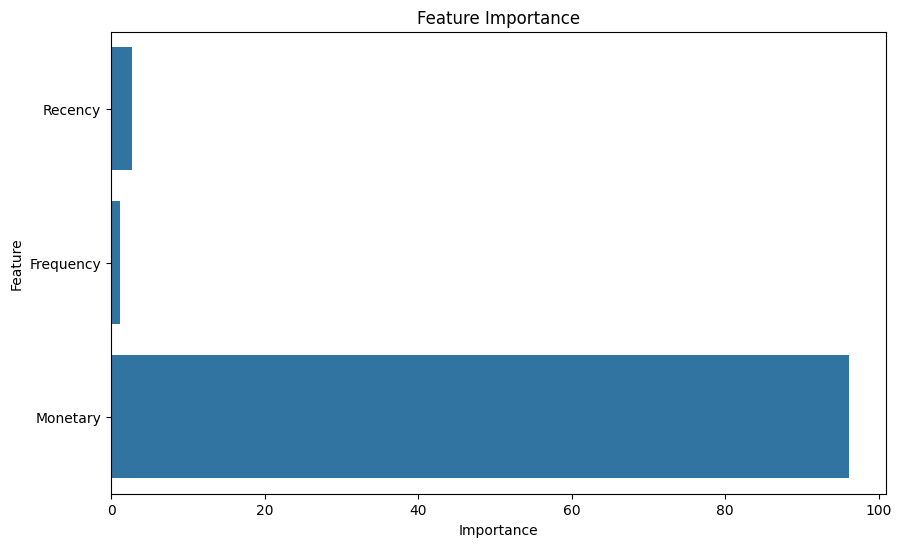

In [12]:
#Visualize Feature Importance
feature_importance = model.get_feature_importance()
features = X.columns

importance_df = pd.DataFrame({'Feature': features, 'Importance': feature_importance})

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Feature Importance')
plt.show()

In [13]:
import ipywidgets as widgets
from IPython.display import display

recency_input = widgets.IntSlider(min=0, max=365, step=1, description='Recency')
frequency_input = widgets.IntSlider(min=0, max=100, step=1, description='Frequency')
monetary_input = widgets.FloatSlider(min=0, max=10000, step=0.01, description='Monetary')

output = widgets.Output()

def make_prediction(recency, frequency, monetary):
    data = pd.DataFrame({'Recency': [recency], 'Frequency': [frequency], 'Monetary': [monetary]})
    prediction = model.predict(data)[0]
    return "Recommend" if prediction == 1 else "Do not recommend"

def update_prediction(change):
    with output:
        output.clear_output()
        prediction = make_prediction(recency_input.value, frequency_input.value, monetary_input.value)
        print(f'Recommendation: {prediction}')

recency_input.observe(update_prediction, names='value')
frequency_input.observe(update_prediction, names='value')
monetary_input.observe(update_prediction, names='value')

display(recency_input, frequency_input, monetary_input, output)


IntSlider(value=0, description='Recency', max=365)

IntSlider(value=0, description='Frequency')

FloatSlider(value=0.0, description='Monetary', max=10000.0, step=0.01)

Output()